# 04 - Pollutant relationships and pollution episodes

**Questions:** how do the six pollutants move together, when do multi-day PM2.5 episodes happen, and which high-PM10 days look dominated by coarse dust?

The dataset has no weather variables, so wind and rain effects are out of scope here (see Limitations).

## 1. Imports

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from seoul_air import config
from seoul_air.episodes import find_episodes
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.METRICS.mkdir(parents=True, exist_ok=True)

In [2]:
hourly = pd.read_parquet(config.DATA_PROCESSED / "air_hourly.parquet")
daily = pd.read_parquet(config.DATA_PROCESSED / "air_daily.parquet")
pollutants = list(config.POLLUTANTS)
city = daily.groupby("date")[pollutants].mean()

## 2. Correlation between pollutants

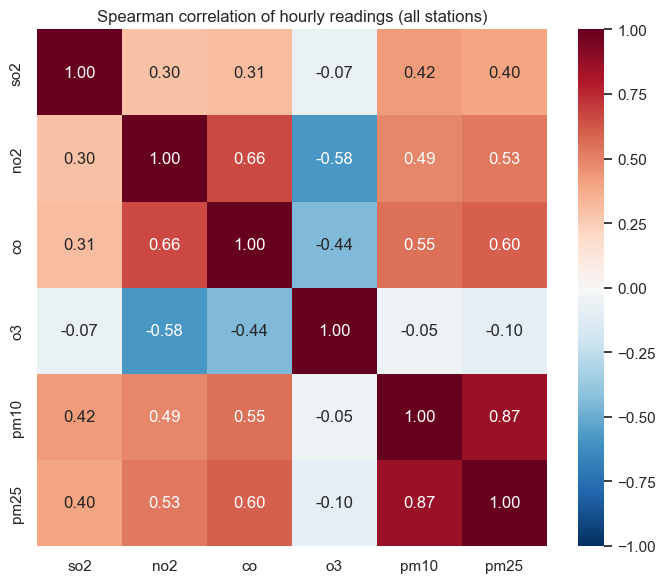

In [3]:
corr = hourly[pollutants].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation of hourly readings (all stations)")
fig.tight_layout()
fig.savefig(config.FIGURES / "04_pollutant_correlation.png", dpi=120)
plt.show()

**Interpretation.** PM2.5 and PM10 are strongly correlated (Spearman 0.87), and both correlate moderately with CO (0.60 and 0.55) and NO2 (0.53 and 0.49), the combustion markers. O3 is negatively correlated with NO2 (-0.58) and CO (-0.44) and almost uncorrelated with particulate matter (-0.10 with PM2.5).

## 3. Ozone and particulate matter peak in different seasons

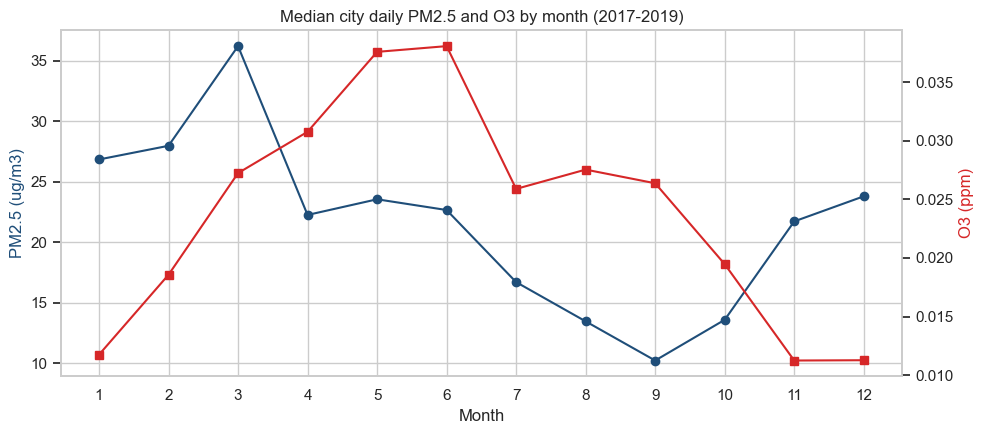

PM2.5 highest month: 3 | O3 highest month: 6


In [4]:
monthly = city.groupby(city.index.month)[["pm25", "o3"]].median()
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(monthly.index, monthly["pm25"], marker="o", color="#1f4e79", label="PM2.5")
ax1.set_ylabel("PM2.5 (ug/m3)", color="#1f4e79")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["o3"], marker="s", color="#d62728", label="O3")
ax2.set_ylabel("O3 (ppm)", color="#d62728")
ax2.grid(False)
ax1.set_xticks(range(1, 13))
ax1.set_xlabel("Month")
ax1.set_title("Median city daily PM2.5 and O3 by month (2017-2019)")
fig.tight_layout()
fig.savefig(config.FIGURES / "04_pm25_vs_o3_season.png", dpi=120)
plt.show()
print("PM2.5 highest month:", monthly["pm25"].idxmax(), "| O3 highest month:", monthly["o3"].idxmax())

**Interpretation.** Particulate matter and ozone peak in different seasons: the city median PM2.5 is highest in March and O3 in June. The air quality problem changes with the season, fine dust in winter and spring, ozone in early summer, so a single indicator does not describe it.

## 4. Multi-day PM2.5 episodes

An **episode** is defined here as a run of at least 2 consecutive days in which the city-wide daily PM2.5 mean is graded Bad or worse (rounded mean above 35 ug/m3). This is a project definition, not an official alert record. Days without a city value (see notebook 01) are not counted as Bad and are left out of the denominator, so a gap ends a run.

In [5]:
runs = find_episodes(city["pm25"])
n_valid = int(city["pm25"].notna().sum())
n_bad = int(runs["days"].sum())
episodes = runs[runs["days"] >= 2].sort_values("days", ascending=False).reset_index(drop=True)
print(f"Bad-or-worse city days: {n_bad} of {n_valid} valid days ({100 * n_bad / n_valid:.1f}%)")
print("Episodes of 2+ days:", len(episodes))
episodes.head(10).round(1)

Bad-or-worse city days: 186 of 1077 valid days (17.3%)
Episodes of 2+ days: 48


,start,end,days,peak_pm25,mean_pm25,gap_before,gap_after
0,2019-02-27,2019-03-07,9,135.2,82.6,False,False
1,2018-03-23,2018-03-30,8,99.0,60.5,False,False
2,2017-03-16,2017-03-21,6,67.3,55.2,False,False
3,2017-03-25,2017-03-30,6,57.0,45.9,False,False
4,2018-01-13,2018-01-18,6,87.8,62.1,False,False
5,2019-02-20,2019-02-25,6,62.2,52.9,False,False
6,2019-01-11,2019-01-15,5,128.7,84.1,False,False
7,2017-01-17,2017-01-20,4,73.7,57.3,False,False
8,2019-12-08,2019-12-11,4,72.1,52.0,False,False
9,2019-12-22,2019-12-25,4,52.1,43.4,False,False


### Runs cut by a gap

A run next to a missing day may be longer than recorded, and two runs on either side of one gap may be a single episode. The first table lists every Bad run that touches a gap, including single days. The second one shows the gap days with their partial city mean from notebook 01, which is a reference only.

In [6]:
cut = runs[runs["gap_before"] | runs["gap_after"]].reset_index(drop=True)
print("Runs next to a gap:", len(cut), "| of these, episodes of 2+ days:", int((cut["days"] >= 2).sum()))
cut.round(1)

Runs next to a gap: 3 | of these, episodes of 2+ days: 1


,start,end,days,peak_pm25,mean_pm25,gap_before,gap_after
0,2019-05-15,2019-05-15,1,44.8,44.8,False,True
1,2019-05-17,2019-05-17,1,39.3,39.3,True,True
2,2019-05-23,2019-05-25,3,54.0,49.6,True,False


In [7]:
gap_days = pd.read_csv(config.METRICS / "01_network_gap_days.csv", parse_dates=["date"])
gap_days.round(1)

,date,hours_with_data,partial_city_mean,raw_pm25_rows
0,2019-03-09,0,NaN,0
1,2019-03-10,0,NaN,0
2,2019-03-11,4,44.4,83
3,2019-03-12,0,NaN,0
4,2019-03-13,0,NaN,0
5,2019-03-14,0,NaN,0
6,2019-03-15,0,NaN,0
7,2019-03-16,0,NaN,0
8,2019-03-17,0,NaN,0
9,2019-05-16,14,43.9,350


**Interpretation.** The longest episode (2019-02-27 to 2019-03-07) is not cut: 2019-03-08 has a valid value of 27.0 ug/m3, so it had ended before the 9-day gap. Three runs touch a gap, all in May 2019. The single Bad days of 2019-05-15 (44.8) and 2019-05-17 (39.3) sit on either side of a gap day whose 14 available hours average 43.9, so they probably form one 3-day episode that the count of 48 misses. The next gap day, 2019-05-18, averages 19.3 over 16 hours, which suggests that this episode did end on 2019-05-17. The episode of 2019-05-23 to 2019-05-25 follows a gap day with a partial mean of 31.5, below the Bad threshold, so it was probably not longer. The rule is kept unchanged and these partial means are used only as a reference. Whether any episode happened during the March gap cannot be known from this dataset.

In [8]:
ep = episodes
season = ep["start"].dt.month.map({12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
                                   6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"})
pd.crosstab(ep["start"].dt.year, season).reindex(columns=["Winter", "Spring", "Summer", "Autumn"], fill_value=0)

start,Winter,Spring,Summer,Autumn
start,,,,
2017,8,5,1,1
2018,8,6,1,3
2019,7,6,2,0


**Interpretation.** The city-wide daily PM2.5 was Bad or worse on 186 of the 1,077 valid days (17.3%), and 48 multi-day episodes were found. The longest one lasted 9 days (2019-02-27 to 2019-03-07, peak 135.2 ug/m3, the highest of the period). Almost all episodes start in winter or spring (8, 8 and 7 winter episodes and 5, 6 and 6 spring episodes per year), and only 4 start in summer over the three years.

## 5. Coarse-dust days

Fine particles (PM2.5) are a subset of PM10. When PM10 is high but the PM2.5 / PM10 ratio is low, coarse particles dominate, which is typical of dust events such as spring yellow dust (hwangsa). Here a **coarse-dust day** is a day with a city PM10 mean graded Bad or worse (above 80 ug/m3) and a PM2.5 / PM10 ratio below 0.4. This is a rule of thumb, not an official yellow-dust record.

In [9]:
city["ratio"] = city["pm25"] / city["pm10"]
print("Median PM2.5 / PM10 ratio by month:")
print(city.groupby(city.index.month)["ratio"].median().round(2).to_frame("ratio").T.to_string())

high_pm10 = city["pm10"].round() > 80
coarse = city[high_pm10 & (city["ratio"] < 0.4)]
print(f"\nValid city days for PM10: {int(city['pm10'].notna().sum())}")
print(f"Days with city PM10 Bad or worse: {int(high_pm10.sum())}; of these, coarse-dust days: {len(coarse)}")
print("Coarse-dust days by month:", coarse.index.month.value_counts().sort_index().to_dict())
coarse[["pm10", "pm25", "ratio"]].sort_values("pm10", ascending=False).head(8).round(2)

Median PM2.5 / PM10 ratio by month:
date     1     2     3     4     5     6     7     8     9     10    11    12
ratio  0.62  0.62  0.65  0.53  0.51  0.64  0.67  0.61  0.51  0.53  0.57  0.61

Valid city days for PM10: 1077
Days with city PM10 Bad or worse: 70; of these, coarse-dust days: 17
Coarse-dust days by month: {1: 2, 2: 2, 4: 3, 5: 6, 10: 2, 11: 2}


,pm10,pm25,ratio
date,,,
2017-05-06,194.36,19.94,0.10
2017-05-08,173.53,36.41,0.21
2017-05-09,124.85,30.52,0.24
2018-04-06,120.81,26.58,0.22
2018-11-28,117.45,21.43,0.18
2017-01-27,106.68,19.18,0.18
2018-05-24,97.55,25.10,0.26
2019-02-06,95.87,34.52,0.36


**Interpretation.** The PM2.5 / PM10 ratio has its lowest monthly medians in May and September (0.51) and April (0.53). Of the 70 days with a city PM10 mean graded Bad or worse, 17 meet the coarse-dust rule, mostly in April and May (9 of the 17); the strongest was 2017-05-06 (PM10 194.4 ug/m3 with a ratio of 0.10). These days fit the pattern of spring dust events. On the remaining high-PM10 days fine particles dominate, which points to combustion and secondary aerosols rather than dust. Confirming yellow dust would require the KMA dust observation records.